# Task 26: Imbalanced Dataset Analysis
Analyzing Credit Card Fraud Detection dataset to understand the impact of class imbalance on model performance.

In [3]:
import os
os.chdir(r'd:\veda\AI-ML-Internship-Tasks\Task26')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay, precision_score,
                              recall_score, f1_score, accuracy_score)

df = pd.read_csv('creditcard.csv')
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Class Distribution Analysis

In [4]:
class_counts = df['Class'].value_counts()
print("Class Distribution:")
print(class_counts)
print(f"\nFraud percentage: {class_counts[1] / len(df) * 100:.4f}%")
print(f"Imbalance ratio: {class_counts[0] / class_counts[1]:.1f}:1")

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage: 0.1727%
Imbalance ratio: 577.9:1


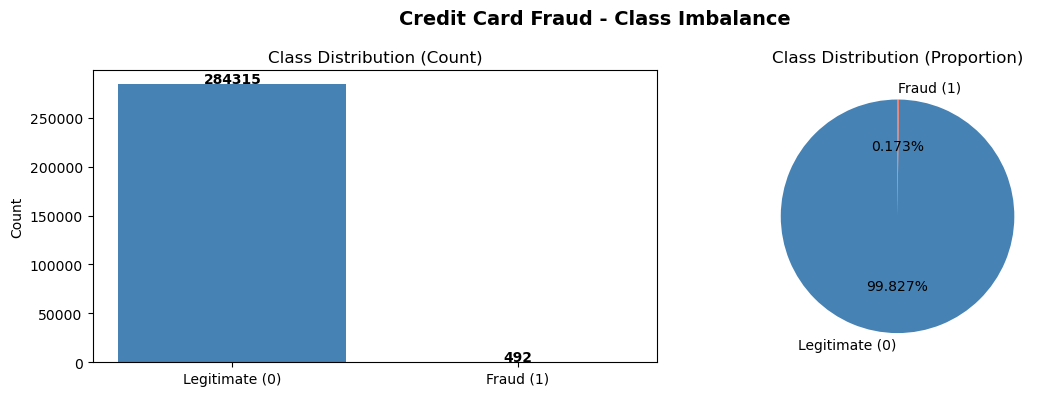

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(['Legitimate (0)', 'Fraud (1)'], class_counts.values, color=['steelblue', 'tomato'])
axes[0].set_title('Class Distribution (Count)')
axes[0].set_ylabel('Count')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 1000, str(v), ha='center', fontweight='bold')

axes[1].pie(class_counts.values, labels=['Legitimate (0)', 'Fraud (1)'],
            autopct='%1.3f%%', colors=['steelblue', 'tomato'], startangle=90)
axes[1].set_title('Class Distribution (Proportion)')

plt.suptitle('Credit Card Fraud - Class Imbalance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. Preprocessing

In [6]:
scaler = StandardScaler()
df['Amount_scaled'] = scaler.fit_transform(df[['Amount']])
df['Time_scaled'] = scaler.fit_transform(df[['Time']])

features = [c for c in df.columns if c not in ['Class', 'Amount', 'Time']]
X = df[features]
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")
print(f"Train fraud count: {y_train.sum()}, Test fraud count: {y_test.sum()}")

Train size: 227845, Test size: 56962
Train fraud count: 394, Test fraud count: 98


## 3. Baseline Classification Model

In [7]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



## 4. Metrics Visualization

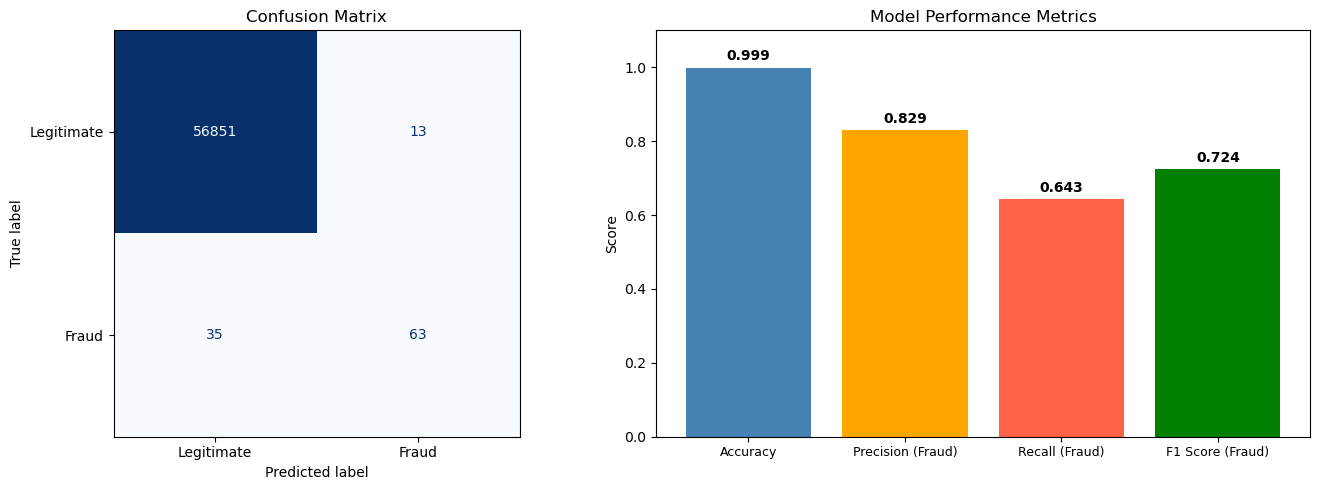

Accuracy              : 0.9992
Precision (Fraud)     : 0.8289
Recall (Fraud)        : 0.6429
F1 Score (Fraud)      : 0.7241


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate', 'Fraud'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix')

metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision (Fraud)': precision_score(y_test, y_pred),
    'Recall (Fraud)': recall_score(y_test, y_pred),
    'F1 Score (Fraud)': f1_score(y_test, y_pred)
}

bars = axes[1].bar(metrics.keys(), metrics.values(), color=['steelblue', 'orange', 'tomato', 'green'])
axes[1].set_ylim(0, 1.1)
axes[1].set_title('Model Performance Metrics')
axes[1].set_ylabel('Score')
axes[1].tick_params(axis='x', labelsize=9)
for bar, val in zip(bars, metrics.values()):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.3f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

for k, v in metrics.items():
    print(f"{k:<22}: {v:.4f}")

## 5. Discussion: Impact of Class Imbalance

**Observations:**
- The dataset has a severe imbalance: **99.83% legitimate** vs **0.17% fraud** (ratio ~578:1).
- The baseline model achieves very high **accuracy (~99%)**, but this is misleading — a model that predicts *everything as legitimate* would also score ~99.83%.
- **Recall for fraud is low**, meaning many actual fraud cases are missed (false negatives), which is costly in real-world fraud detection.
- **Precision and F1 score** for the fraud class reveal the true weakness of the model.

**Why accuracy alone is misleading:**
- With 284,315 legitimate vs 492 fraud transactions, predicting all as legitimate gives 99.83% accuracy but catches 0 frauds.
- Metrics like **Recall, Precision, and F1** on the minority class are far more informative.

**Strategies to handle imbalance (not implemented here):**
- Oversampling minority class (SMOTE)
- Undersampling majority class
- Using `class_weight='balanced'` in the model
- Using AUC-ROC as the evaluation metric